# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

**Student SRN:** pes2ug24cs513

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Markdown cells marked **Reflection** are answered below. The ground-truth `labels` array is used only to evaluate the segmentation, never to locate the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**Completed:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# 1. Voxel count and storage at 16 bits (2 bytes) per voxel
nx, ny, nz = 512, 512, 300
n_voxels = nx * ny * nz
scan_mb = n_voxels * 2 / 1_000_000  # decimal MB

# 2. Physical extent (x, y, z) and voxel volume
extent_mm = (nx * 0.5, ny * 0.5, nz * 1.0)
voxel_mm3 = 0.5 * 0.5 * 1.0

# 3. One front-view ray per x-z pixel; each ray samples one step per y voxel
samples_per_frame = nx * nz * ny
samples_video = samples_per_frame * 120

# 4. With early ray termination, each ray averages 35% of its full samples
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 157.3 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** Ignoring anisotropic spacing would make distances and shapes wrong in coronal and sagittal views: each z step is 4 mm while each in-plane x or y step is 3 mm, so anatomy would be stretched or compressed vertically. Measurements and apparent lesion shape would also be inaccurate because the displayed voxel geometry would not match its physical size.

_Your answer:_

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**Completed:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

Candidate voxels: 431; connected components: 1; lesion component: 431
Lesion centroid (z, y, x): (28, 40, 41)
Evaluation only — distance from ground-truth centroid: 2.92 mm


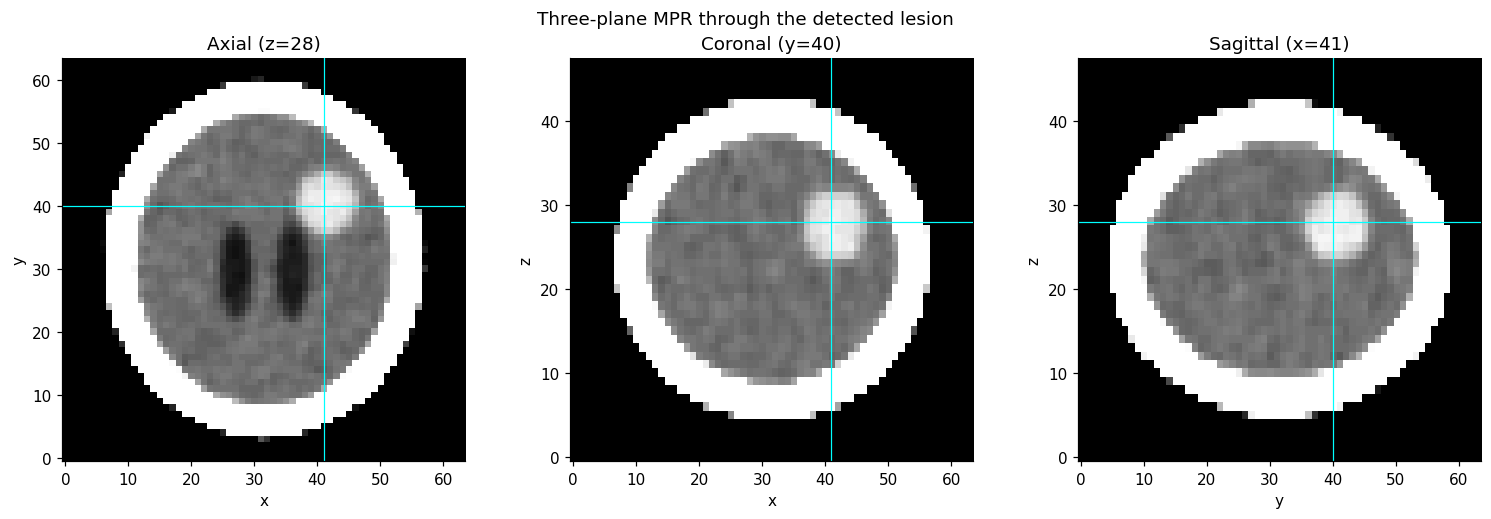

In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# 1. Candidate intensities constrained to the eroded interior of the skull
bone = vol > 300
inside = ndimage.binary_fill_holes(bone) & ~bone
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside

# 2. Keep the largest connected candidate region and find its integer centroid
components, n_components = ndimage.label(candidates)
component_sizes = np.bincount(components.ravel())
component_sizes[0] = 0
largest_id = int(component_sizes.argmax())
lesion = components == largest_id
cz, cy, cx = (int(round(v)) for v in ndimage.center_of_mass(lesion))
print(f"Candidate voxels: {int(candidates.sum()):,}; connected components: {n_components}; lesion component: {int(lesion.sum()):,}")
print(f"Lesion centroid (z, y, x): ({cz}, {cy}, {cx})")

# 3. Orthogonal MPR slices with window/level and crosshairs
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
axes[0].imshow(window(vol[cz, :, :], 80, 40), cmap="gray", origin="lower", aspect=1)
axes[0].axhline(cy, color="cyan", lw=0.8); axes[0].axvline(cx, color="cyan", lw=0.8)
axes[0].set(title=f"Axial (z={cz})", xlabel="x", ylabel="y")
axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap="gray", origin="lower", aspect=ASPECT)
axes[1].axhline(cz, color="cyan", lw=0.8); axes[1].axvline(cx, color="cyan", lw=0.8)
axes[1].set(title=f"Coronal (y={cy})", xlabel="x", ylabel="z")
axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap="gray", origin="lower", aspect=ASPECT)
axes[2].axhline(cz, color="cyan", lw=0.8); axes[2].axvline(cy, color="cyan", lw=0.8)
axes[2].set(title=f"Sagittal (x={cx})", xlabel="y", ylabel="z")
fig.suptitle("Three-plane MPR through the detected lesion")
plt.tight_layout(); plt.show()

# 4. Evaluation only: physical distance to the provided ground-truth centroid
truth_centroid = np.array(ndimage.center_of_mass(labels == 5))
detected_centroid = np.array([cz, cy, cx], dtype=float)
distance_mm = np.linalg.norm((detected_centroid - truth_centroid) * np.array(SPACING))
print(f"Evaluation only — distance from ground-truth centroid: {distance_mm:.2f} mm")

**Reflection:** Erosion removes the thin partial-volume shell along the skull boundary, where a voxel mixes bone, CSF, and brain and can have an intermediate HU value that overlaps the lesion's range. Without erosion, those mixed boundary voxels could connect unrelated tissue to the candidate lesion and shift its centroid. HU alone cannot perfectly separate materials because their intensity ranges overlap.

_Your answer:_

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**Completed:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

 threshold_HU  voxels  volume_mL  Dice_eval_only
           45     535     19.260        0.928929
           50     464     16.704        0.993534
           55     431     15.516        0.963128
           60     350     12.600        0.859951
           65     273      9.828        0.740841
           70     170      6.120        0.536278
Report a threshold-sensitive range of 6.12–19.26 mL; evaluation-best threshold is 50 HU (16.70 mL, Dice 0.994).


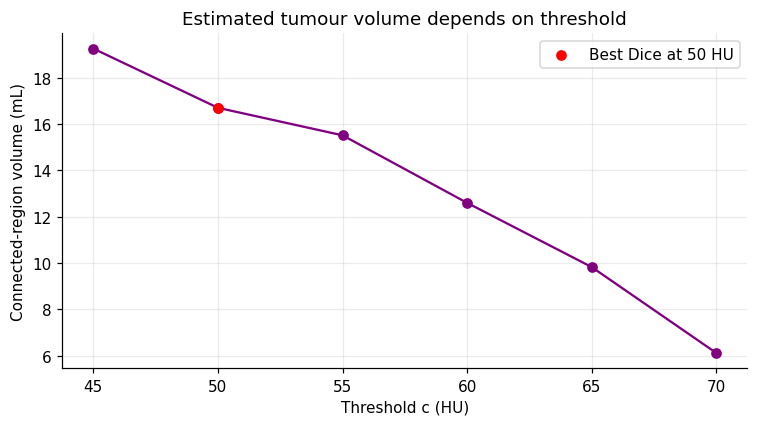

In [4]:
truth = labels == 5
rows = []
# 1–2. At each threshold, keep the connected region containing the detected lesion centre
for c in [45, 50, 55, 60, 65, 70]:
    components_c, _ = ndimage.label(vol > c)
    region_id = int(components_c[cz, cy, cx])
    region = components_c == region_id if region_id != 0 else np.zeros_like(truth)
    n = int(region.sum())
    dice = 2 * int((region & truth).sum()) / (n + int(truth.sum())) if n + int(truth.sum()) else 0.0
    rows.append({"threshold_HU": c, "voxels": n, "volume_mL": n * VOXEL_MM3 / 1000, "Dice_eval_only": dice})

table = pd.DataFrame(rows)
display(table)

# 3. Plot threshold sensitivity and identify the evaluation-best threshold
best_row = table.loc[table["Dice_eval_only"].idxmax()]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table["threshold_HU"], table["volume_mL"], marker="o", color="purple")
ax.scatter([best_row["threshold_HU"]], [best_row["volume_mL"]], color="red", zorder=3, label=f"Best Dice at {int(best_row['threshold_HU'])} HU")
ax.set(xlabel="Threshold c (HU)", ylabel="Connected-region volume (mL)", title="Estimated tumour volume depends on threshold")
ax.grid(alpha=0.25); ax.legend()
plt.tight_layout(); plt.show()

# 4. Report the measured range across the requested thresholds
volume_min, volume_max = table["volume_mL"].min(), table["volume_mL"].max()
print(f"Report a threshold-sensitive range of {volume_min:.2f}–{volume_max:.2f} mL; evaluation-best threshold is {int(best_row['threshold_HU'])} HU ({best_row['volume_mL']:.2f} mL, Dice {best_row['Dice_eval_only']:.3f}).")

**Reflection:** Without ground truth, I would choose the threshold whose boundary best matches the lesion across all three MPR planes, using the clinical window/level and radiologist review; I would document the chosen HU threshold and segmentation method. I would report the measured range across plausible thresholds alongside the preferred estimate, and show an overlay or boundary band for the smallest and largest plausible regions. That makes the uncertainty visible instead of presenting one threshold-derived volume as exact.

_Your answer:_

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**Completed:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

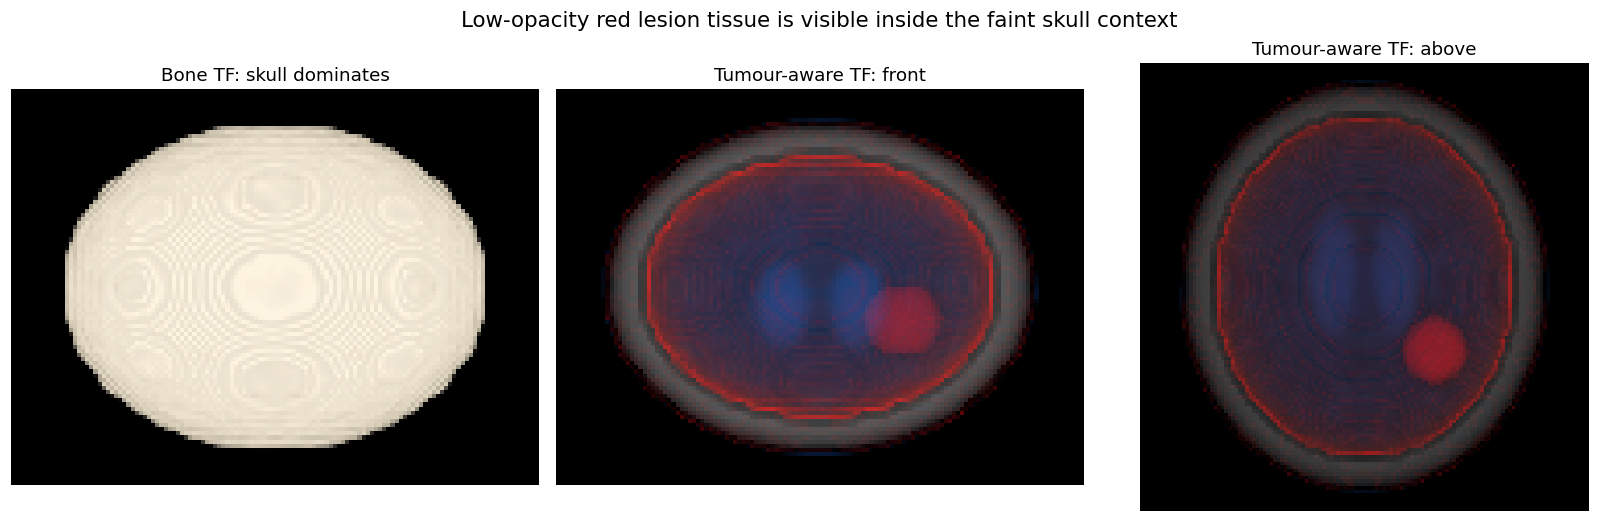

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# 2. Transparent air/soft tissue, faint blue CSF, nearly transparent bone, red lesion-range tissue
# The tumour range overlaps brain HU, so use low per-sample opacity to limit occlusion.
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0), (4, (0, 0, 0), 0.0),
    (5, (0.15, 0.45, 1.0), 0.012), (20, (0.15, 0.45, 1.0), 0.012),
    (54, (0, 0, 0), 0.0), (55, (1.0, 0.05, 0.05), 0.045),
    (90, (1.0, 0.05, 0.05), 0.045), (120, (0, 0, 0), 0.0),
    (399, (0, 0, 0), 0.0), (400, (0.85, 0.85, 0.85), 0.008),
    (1500, (1, 1, 1), 0.01)
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# 1 & 3. Bone-only front view, then tumour-aware front and top views
C, A = render(vol, bone_tf, axis=1)
axes[0].imshow(np.clip(C, 0, 1)); axes[0].set_title("Bone TF: skull dominates")
C, A = render(vol, tumour_tf, axis=1)
axes[1].imshow(np.clip(C, 0, 1)); axes[1].set_title("Tumour-aware TF: front")
C, A = render(vol, tumour_tf, axis=0)
axes[2].imshow(np.clip(C, 0, 1)); axes[2].set_title("Tumour-aware TF: above")
for ax in axes: ax.axis("off")
# 4. Conclusion-style title
fig.suptitle("Low-opacity red lesion tissue is visible inside the faint skull context", fontsize=14)
plt.tight_layout(); plt.show()

**Reflection:** The faint red rim is caused by occlusion and overlapping intensity ranges: ordinary brain or partial-volume voxels can fall in the same HU interval as the lesion, and opacity accumulates along each ray. A lecture technique that can remove this ambiguity is segmentation followed by an isosurface or segmentation overlay (Slides 31–32), using the connected lesion region to isolate its boundary. A transfer function alone maps each voxel by intensity and cannot distinguish two tissues that share the same HU value or use spatial connectivity.

_Your answer:_

**Reflection (final):** The detected lesion is near the centre at voxel (z=28, y=40, x=41), approximately 112, 120, and 123 mm along the scan axes using the dataset spacing. Its connected-region estimate ranges from about 6.1 to 19.3 mL across the tested thresholds; 50 HU gives the best evaluation Dice and an estimate of about 16.7 mL. I would open with the three-plane MPR because orthogonal slices expose internal structure and show the lesion boundary without 3-D occlusion. I would then use the segmentation overlay to discuss the threshold-dependent measurement and the 3-D render to orient the board to surrounding anatomy. The 3-D render remains limited by overlapping HU ranges and accumulated opacity, so its apparent red boundary is not a definitive segmentation.

_Your final note here:_